# Value-axis model: a convolution along the attribute values (I-RAVEN-X 3×10, values 0–50)

Every attribute **value** is a constant of the template (`v0 … v50`), and a panel's attribute is a fact
`x(P, A, v17)`. Background facts give the values their structure: `off(U, V, k)` for V = U + k (k = −2…2) and
`plus(U, W, V)` for U + W = V. No rule names a value, so every rule is the same at every value, the way a CNN is the
same at every pixel (notes §27, FINDINGS items 25–27).

* **The kernel** stamps five learned codes around each panel's value: `h(P, A, V)` means "V is k above P's value".
* **Comparing panels** at every value and summing over the values gives a code of their *offset*, not their values.
* **The answer** is scored at every value by the same two layers (a 1×1 convolution), from the rule the context
  points to, the offset from the last panel, the value counts per row, and the exact sums.

It is closer to the symbolic template than to the facet model: the primitives (sums, counts, offsets of ±2) are given,
and it learns which rule applies and how to combine them. Weights: `experiments/valaxis_n10_m50_plus` (6000 training
puzzles, the epoch picked on puzzles 6000–6299); everything below is on unseen puzzles 6300+.

Sections: 1. a puzzle · 2. the template · 3. the graph of this puzzle · 4. the kernel · 5. generating the answer ·
6. the value symmetry · 7. all runs.

In [1]:
import os, sys, json, glob, re, warnings
from collections import Counter
warnings.filterwarnings("ignore", message="IProgress not found")
import numpy as np
from IPython.display import display
if os.path.basename(os.getcwd()) == "notebooks": os.chdir("..")   # paths below are relative to the repo root
sys.path.insert(0, os.path.abspath("pynl"))
import neuralogic
neuralogic.set_max_memory_size(16)
from neuralogic.logging import clear_handlers; clear_handlers()
from neuralogic.core import R, Settings
from neuralogic.dataset import Dataset, Sample
from neuralogic.nn import Adam, MSE
import bench_hub_grounding as B          # data loading, scoring
import value_axis as VA                  # the value-axis template, facts, scoring
import facet_viz as FV, value_axis_viz as VV

IRX, CKPT = "data/iravenx/center_single_shuffle_n_10_maxval_50.json", "experiments/valaxis_n10_m50_plus"
B.configure(n_cols=10, maxval=50)
data, rules = B.load_iravenx(IRX, 6300, 300), VA.rules_of(IRX, 6300, 300)
settings = lambda: Settings(optimizer=Adam(lr=1e-3), error_function=MSE(), iso_value_compression=False, chain_pruning=False)
def sample(pz, y, gid, maxval=50):
    return Sample(R.out(gid)[VA.value_target([pz[B.N_CTX + y][0]], maxval).tolist()], VA.value_facts(pz, gid))
def load(ckpt, maxval=50):
    a = json.load(open(f"{ckpt}/best.json"))["args"]
    m = VA.build_value_template(a["dim"], maxval, plus=not a["no_plus"], per_value=a.get("per_value", False))
    m.build(settings()); m.load(f"{ckpt}/template_best.bin")
    return m
print(len(data), "unseen puzzles loaded")

300 unseen puzzles loaded


## 1. A puzzle (unseen: 6301)

I-RAVEN-X shows the last three rows of a 10×10 matrix: two complete rows and a question row of nine panels. Each
panel holds one object; its type, size and colour each follow a rule along the rows.

In [2]:
IDX = 1                                      # puzzle 6301
pz, y, _ = data[IDX]
answer = pz[B.N_CTX + y][0]
print(f"puzzle {6300 + IDX}, answer: candidate {y}")
for a in VA.ATTRS:
    r = rules[IDX][a.capitalize()]
    print(f"\n{a}: {r}" + "".join(f"\n   row {k + 1}: " + " ".join(f"{pz[k * 10 + c][0][a]:2d}" if k * 10 + c < B.N_CTX else " ?"
                                                                for c in range(10)) for k in range(3)) + f"   -> answer {answer[a]}")

puzzle 6301, answer: candidate 7

type: Progression
   row 1: 17 16 15 14 13 12 11 10  9  8
   row 2: 29 28 27 26 25 24 23 22 21 20
   row 3: 17 16 15 14 13 12 11 10  9  ?   -> answer 8

size: Arithmetic
   row 1: 36  0  0  0 19  0  0  7  5  5
   row 2: 38  0  0  0  6  0  0 20  2 10
   row 3: 32  0  0  2 10  4  8  0  4  ?   -> answer 4

color: Arithmetic
   row 1:  0  8 14  7  0  7  1  0  1 38
   row 2:  1 19  1  0  0  0  0  0  5 26
   row 3:  0  0  0  0 17  2 17  0  2  ?   -> answer 38


Type falls by 1 per panel (Progression). Size has the minus form of Arithmetic (first = sum of the rest:
32 = 0+0+2+10+4+8+0+4 + answer, so the answer is 4). Colour has the plus form (last = sum of the rest: 17+2+17+2 = 38).

## 2. The template

The background facts are the value axis: 51 values, 249 offsets within ±2, and 1,326 sums U + W = V within 0–50. They
are facts of the template, not weights, and are left out of the listing below. Every rule has the attribute `A` and
the value `V` as variables, so one set of weights serves all three attributes and all 51 values. `*` marks hidden
structural atoms (they only bind variables); `{m, n}` is a learned weight matrix.

In [3]:
template = VA.build_value_template(32, 50)
lines = str(template).splitlines()
facts = Counter(l[:l.find("(")] for l in lines if l.startswith(("val(", "off(", "plus(")))
print("background facts:", ", ".join(f"{k} {n}" for k, n in facts.items()), "\n")
print("\n".join(l for l in lines if not l.startswith(("val(", "off(", "plus("))))

background facts: val 51, off 249, plus 1326 

h(P, A, V) :- {32, 1} x(P, A, U), *off(U, V, om2).
h(P, A, V) :- {32, 1} x(P, A, U), *off(U, V, om1).
h(P, A, V) :- {32, 1} x(P, A, U), *off(U, V, op0).
h(P, A, V) :- {32, 1} x(P, A, U), *off(U, V, op1).
h(P, A, V) :- {32, 1} x(P, A, U), *off(U, V, op2).
h/3 [transformation=identity]
pv(P, Q, A, V) :- *next(P, Q), {32, 32} h(P, A, V).
pv(P, Q, A, V) :- *next(P, Q), {32, 32} h(Q, A, V).
pv/4 [transformation=tanh]
pd(P, Q, A) :- {32, 32} pv(P, Q, A, V). [aggregation=sum]
pd/3 [transformation=tanh]
rd(Rw, A) :- *inrow(P, Rw), {32, 32} pd(P, Q, A). [aggregation=avg]
rd/2 [transformation=tanh]
pr(Rw, A, V) :- *inrow(P, Rw), x(P, A, V). [aggregation=sum]
pr/3 [transformation=identity]
pb(Rw, A, V) :- *inrow(P, Rw), x(P, A, V). [aggregation=max]
pb/3 [transformation=identity]
nd(Rw, A) :- pb(Rw, A, V). [aggregation=sum]
nd/2 [transformation=identity]
ov(Rw, A) :- *full(Rw), pb(Rw, A, V), pb(r3, A, V). [combination=elproduct, aggregation=sum]
ov/2

In [4]:
model = load(CKPT)
weights = model.state_dict()["weights"]
per_pred = Counter()
for l in lines:
    if ":-" in l:
        per_pred[l[:l.find("(")]] += sum(int(a) * int(b) for a, b in re.findall(r"\{(\d+), (\d+)\}", l))
print("learned weights:", sum(int(np.size(v)) for v in weights.values()), "| per predicate:",
      ", ".join(f"{p} {n}" for p, n in per_pred.most_common() if n))

learned weights: 10817 | per predicate: ctx 2240, o 2176, pv 2048, ctx2 1056, o2 1056, pd 1024, rd 1024, h 160, s 33


## 3. The graph of this puzzle

PyNeuraLogic grounds the template on the puzzle's facts into a network (`FV.ground_graph`); the pictures draw that
network for one attribute, with every ground atom placed by its own arguments. Nothing is drawn that the grounding
does not contain.

* **Lanes** are the 29 context panels, (row, column) and the panel's value. Black: the panel's value `x`.
  Purple: the kernel atoms `h`, only within ±2 of the value. Lilac, between two lanes: the comparison `pv` of
  neighbouring panels at each value.
* **Green squares** on the right are value-free: a pair's offset code `pd` (one per neighbouring pair), each row's
  descriptor `rd`, distinct values `nd`, overlap `ov`, the plus / minus checks, and the context `ctx`.
* **Orange paths** are the exact running sums along each row (`acc` for plus, `accm` for minus). They exist only
  while the sum stays within 0–50.
* **Blue** dots under each row: how many panels of that row hold each value.
* **Output lane**: one node per value (the scoring layers `o`, `o2`, `s` merged), fed by the context (the light fan),
  the last panel's kernel atoms (purple), the counts and the sums. The bars are the trained model's probabilities.

Colour (Arithmetic, plus form): the row-3 sum reaches 38, and the output follows it.

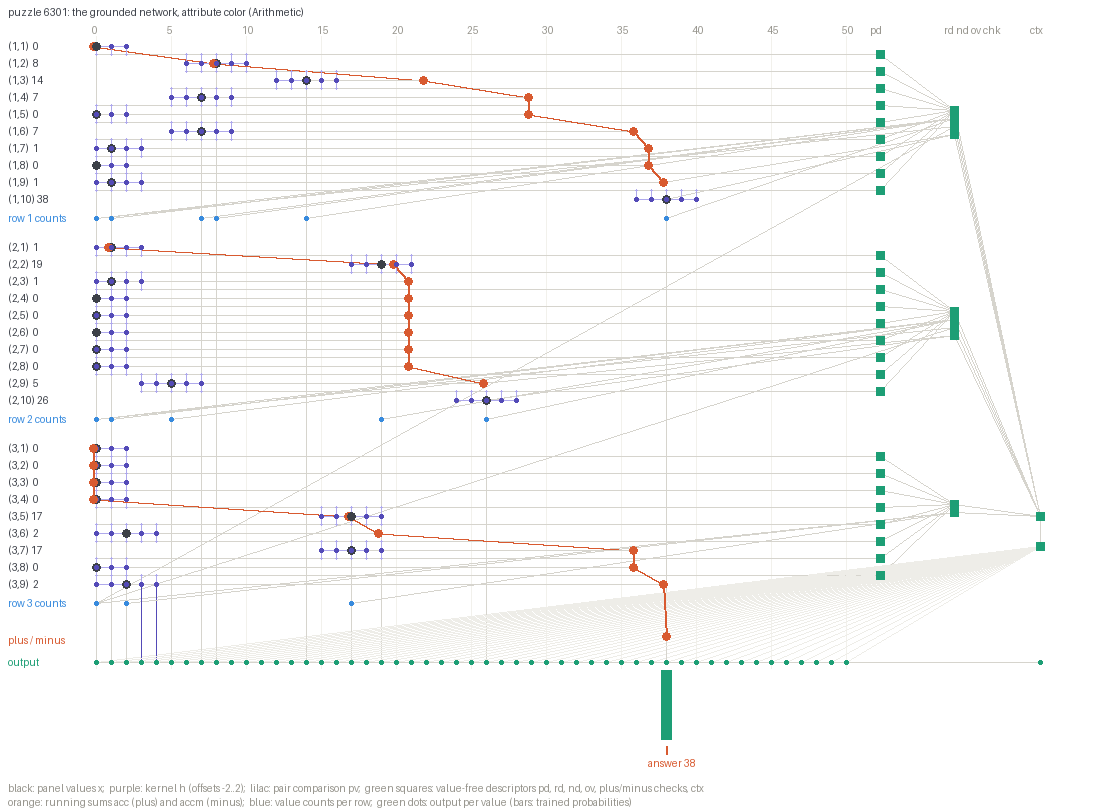

color: 564 ground atoms drawn


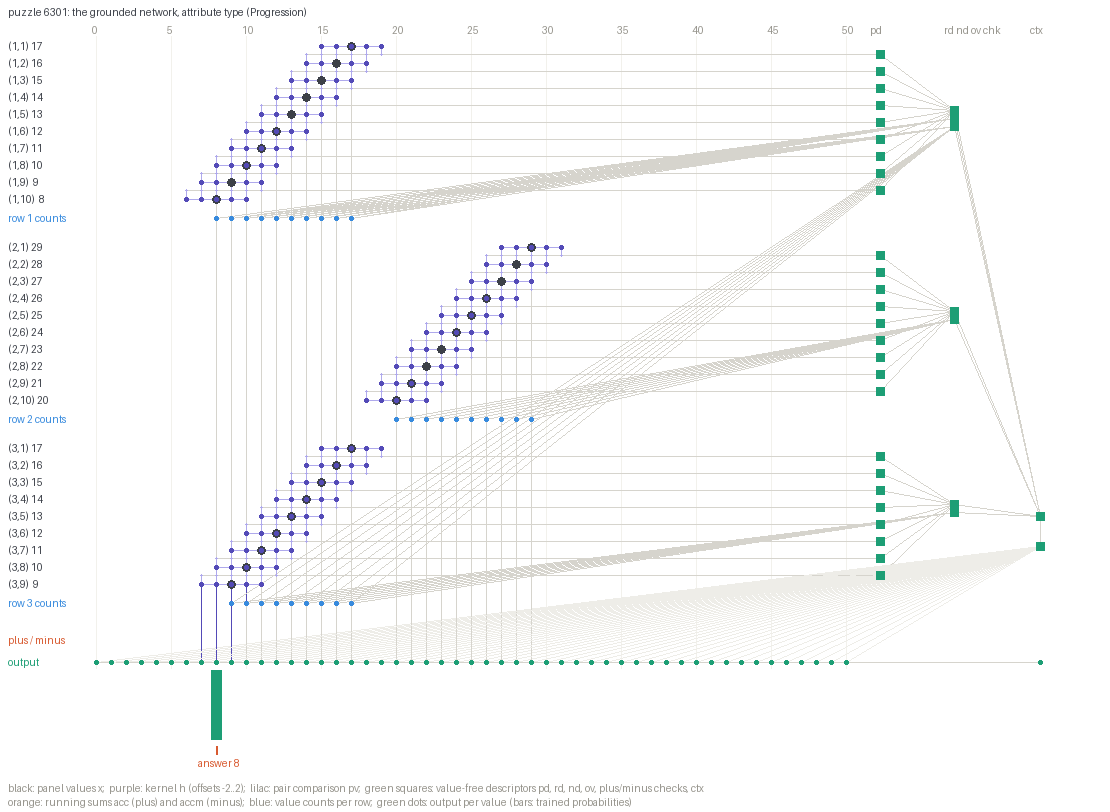

type: 577 ground atoms drawn

the whole network (three attributes): 1718 ground atoms, 3041 atom-to-atom edges
  acc 27, accm 26, ctx 3, ctx2 3, dist 3, h 379, ma 1, mchk 2, nd 9, o 153, o2 153, one 1, out 1, ov 5, pb 60, pchk 2, pd 78, pr 60, pv 502, rd 9, s 153, sa 1, x 87


In [5]:
edges = FV.ground_graph(VA.build_value_template(32, 50), VA.value_facts(pz, "g"), "g", out_len=153)
probs = np.asarray(model.test(list(model.build_dataset(Dataset([sample(pz, y, "q")]))))[0], dtype=float).reshape(3, 51)
for a in ("color", "type"):
    img, n = VV.draw_value_graph(pz, edges, a, probs=probs[VA.ATTRS.index(a)], answer=answer[a],
                                 title=f"puzzle {6300 + IDX}: the grounded network, attribute {a} ({rules[IDX][a.capitalize()]})")
    display(img)
    print(f"{a}: {n} ground atoms drawn")
atoms = Counter(e[:e.find("(")] if "(" in e else e for e in {a for ed in edges for a in ed})
print(f"\nthe whole network (three attributes): {sum(atoms.values())} ground atoms, {len(edges)} atom-to-atom edges")
print("  " + ", ".join(f"{p} {n}" for p, n in sorted(atoms.items())))

Type (Progression, step −1): the sums run off the axis, so no orange path reaches the output; the answer comes
from the kernel atoms of the last panel (value 9): the output fires one below it, at 8, because the row descriptors
say "step −1".

## 4. The kernel

Five learned codes of 32 numbers, one per offset −2…+2 (160 weights). Each panel has one value, so the convolution
just stamps them around it. Their job is to tell the offsets apart; the layers that read them do the rest. How alike
two codes are varies between runs: here −0.47 to 0.5 (the codes of −1 and +1 are the most alike), in the 600-puzzle
run −0.38 to 0.07, close to random 32-number vectors.

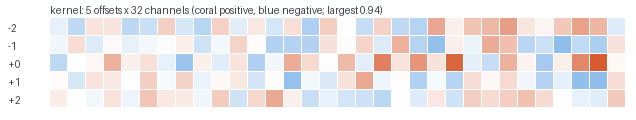

lengths [1.64 1.53 2.16 1.37 1.22] 
cosine similarity between offsets -2..+2:
 [[ 1.   -0.16  0.26 -0.27  0.21]
 [-0.16  1.   -0.3   0.5  -0.04]
 [ 0.26 -0.3   1.   -0.47 -0.36]
 [-0.27  0.5  -0.47  1.    0.17]
 [ 0.21 -0.04 -0.36  0.17  1.  ]]


In [6]:
K = np.array([np.asarray(weights[k], dtype=float).flatten() for k in list(weights)[:5]])
display(VV.draw_kernel(K))
c = K @ K.T / np.outer(np.linalg.norm(K, axis=1), np.linalg.norm(K, axis=1))
print("lengths", np.linalg.norm(K, axis=1).round(2), "\ncosine similarity between offsets -2..+2:\n", c.round(2))

## 5. Generating the answer

The model outputs a distribution over the 51 values for each attribute. *Exact* compares the most likely value with the
answer's; *matched* picks the candidate closest to the generated distribution (turned into the facet model's
thermometer codes, so the numbers compare with the facet model's).

In [7]:
for a, p in zip(VA.ATTRS, probs):
    top = np.argsort(-p)[:3]
    print(f"puzzle {6300 + IDX} {a:5s}: answer {answer[a]:2d} | " + ", ".join(f"p({v}) = {p[v]:.3f}" for v in top))
outs = model.test(list(model.build_dataset(Dataset([sample(p, yy, f"u{i}") for i, (p, yy, _) in enumerate(data)]))))
matched, exact, ties, allv, hits = VA.score(outs, data, rules, 50)
print(f"\n{len(data)} unseen puzzles: matched {100 * matched / len(data):.1f}%, exact {100 * exact['all'] / len(data):.1f}%")
for r in VA.RULES:
    print(f"   exact value, {r:16s} {100 * hits[r][0] / hits[r][1]:5.1f}%  (of {hits[r][1]})")

puzzle 6301 type : answer  8 | p(8) = 1.000, p(10) = 0.000, p(7) = 0.000
puzzle 6301 size : answer  4 | p(4) = 1.000, p(5) = 0.000, p(6) = 0.000
puzzle 6301 color: answer 38 | p(38) = 1.000, p(1) = 0.000, p(4) = 0.000



300 unseen puzzles: matched 100.0%, exact 99.0%
   exact value, Constant         100.0%  (of 271)
   exact value, Progression      100.0%  (of 234)
   exact value, Distribute_Three 100.0%  (of 260)
   exact value, Arithmetic       100.0%  (of 135)


## 6. The value symmetry

Moving every value of an attribute by k moves the output by k: no rule names a value, so by the theorem of notes §21.2
the network of the shifted puzzle is the same network, renamed. The plus relation is the exception: (u+k) + (w+k) ≠
(u+w) + k, so where a shift changes a sum, the output may change too. Below, type values of the puzzles whose type is
not Arithmetic are moved by +3, with the trained model and with the model trained without plus.

The same weights also run on a value range never seen in training: no weight belongs to a value.

In [8]:
def shifted(p, a, k): return [[{**o, a: o[a] + k} for o in q] for q in p]
keep = [(p, yy, c) for (p, yy, c), r in zip(data, rules) if r["Type"] != "Arithmetic"
        and 2 <= min(o["type"] for q in p[:B.N_CTX] for o in q) and max(o["type"] for q in p[:B.N_CTX] for o in q) + 3 <= 48]
for name, ckpt in (("with plus", CKPT), ("without plus", "experiments/valaxis_n10_m50_noplus")):
    m = load(ckpt)
    o0 = m.test(list(m.build_dataset(Dataset([sample(p, yy, f"a{i}") for i, (p, yy, _) in enumerate(keep)]))))
    o1 = m.test(list(m.build_dataset(Dataset([sample(shifted(p, "type", 3), yy, f"b{i}") for i, (p, yy, _) in enumerate(keep)]))))
    d = [np.abs(np.roll(np.asarray(x0, float).reshape(3, 51)[0], 3) - np.asarray(x1, float).reshape(3, 51)[0]).max() for x0, x1 in zip(o0, o1)]
    print(f"{name:13s}: {len(keep)} puzzles, type moved by +3: output moved by +3 with max |difference| {max(d):.1e}; exact (< 1e-12) in {sum(x < 1e-12 for x in d)}")

with plus    : 146 puzzles, type moved by +3: output moved by +3 with max |difference| 1.4e-07; exact (< 1e-12) in 139


without plus : 146 puzzles, type moved by +3: output moved by +3 with max |difference| 4.4e-16; exact (< 1e-12) in 146


In [9]:
IRX100 = "data/iravenx/center_single_shuffle_n_10_maxval_100.json"
B.configure(n_cols=10, maxval=100)
d100, r100 = B.load_iravenx(IRX100, 6300, 300), VA.rules_of(IRX100, 6300, 300)
m100 = load(CKPT, maxval=100)                 # the same weights, a template with values 0..100
o100 = m100.test(list(m100.build_dataset(Dataset([sample(p, yy, f"c{i}", 100) for i, (p, yy, _) in enumerate(d100)]))))
matched, exact, ties, allv, hits = VA.score(o100, d100, r100, 100)
print(f"values 0-100, never seen in training: {len(d100)} unseen puzzles, matched {100 * matched / len(d100):.1f}%, "
      f"exact {100 * exact['all'] / len(d100):.1f}%; exact value per rule " + " / ".join(f"{100 * hits[r][0] / hits[r][1]:.1f}" for r in VA.RULES))
B.configure(n_cols=10, maxval=50)

values 0-100, never seen in training: 300 unseen puzzles, matched 100.0%, exact 100.0%; exact value per rule 100.0 / 100.0 / 100.0 / 100.0


## 7. All runs (1000 unseen puzzles each, from the runs' `best.json`)

* `plus*`: the model above at 6000 / 600 / 100 training puzzles.
* `noplus`: without the plus relation. The convolution keeps Constant, Progression and Distribute; Arithmetic falls
  to chance-like levels: a kernel of ±2 cannot add.
* `pervalue*`: the ablation of the value symmetry. Every rule with weights is written once per value, with its own
  weights (335k weights); the primitives are the same. Without sharing across values, each value's scoring layers
  learn from the few puzzles whose answer is near that value.

For comparison, the facet model with column roles: 94.1% matched, 29.0% exact, with 288k weights and 6000 puzzles.

In [10]:
print(f"{'run':14s} {'weights':>8s} {'epoch':>5s} | matched  exact | exact value: Constant Progression Distribute Arithmetic")
for f in sorted(glob.glob("experiments/valaxis_n10_m50_*/best.json")):
    b, run = json.load(open(f)), f.split("/")[1].replace("valaxis_n10_m50_", "")
    u, last = b["unseen"], json.load(open(f.replace("best.json", "history.json")))[-1]["epoch"]
    print(f"{run:14s} {b['weights']:8d} {b['epoch']:5d} | {100 * u['matched']:6.1f} {100 * u['exact']:6.1f} | "
          + "  ".join(f"{100 * u['per_rule'][r]:9.1f}" for r in VA.RULES)
          + ("   (300 unseen)" if run == "smoke" else "")
          + (f"   (still training: epoch {last} of {b['args']['train_epochs']})" if last < b["args"]["train_epochs"] else ""))

run             weights epoch | matched  exact | exact value: Constant Progression Distribute Arithmetic
noplus            10689    45 |   84.0   58.4 |     100.0      100.0      100.0       11.1
pervalue         335475    40 |   98.4   95.7 |     100.0      100.0      100.0       94.9
pervalue100      335475    40 |   38.3    3.6 |      60.5       30.8       21.4       22.3
pervalue600      335475   190 |   92.7   79.5 |      98.0       87.8       97.7       86.8
plus              10817     5 |  100.0   98.4 |     100.0      100.0      100.0      100.0
plus100           10817    30 |   99.0   95.5 |      99.9       98.5      100.0       97.2
plus600           10817    10 |   99.9   98.3 |     100.0      100.0      100.0       99.8
smoke             10817     5 |   99.3   98.3 |     100.0      100.0      100.0       98.5   (300 unseen)
